# Lag Uncertainty and Bayesian Model Averaging

How does the lag-order decision affect inference about persistence and shock transmission? [Executive summary](../EXECUTIVE_SUMMARY.md) | [Methods](../docs/methods.md) | [Research report](../docs/lag_uncertainty_model_averaging.pdf)

The supplied series has an unverified generating process. All results are conditional on the declared models, priors, and common conditioning observations.

In [1]:
from pathlib import Path
import json
import os
import numpy as np
import pandas as pd
from IPython.display import Image, display
from lag_uncertainty import ModelAveragedInference
from lag_uncertainty.study import LagOrderStudy

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'project4', Path.cwd().parent / 'project4']
PROJECT = next(p for p in candidates if (p / 'results/study_summary.json').is_file())
RESULTS = PROJECT / 'results'
if os.environ.get('RUN_ESTIMATION') == '1':
    if not os.environ.get('AR_DATA'):
        raise ValueError('Set AR_DATA to the explicit source CSV path for an intentional rerun')
    LagOrderStudy(os.environ['AR_DATA'], RESULTS).run()
load = lambda name: json.loads((RESULTS / name).read_text())
load('data_manifest.json')

{'source_file': 'sim_arma_data.csv',
 'source_sha256': '27c539ef347e267b68611499b7b7c810fc8144a91cf82ceb279a1d7550bbbd5c',
 'header': None,
 'observations': 200,
 'conditioning_observations': 8,
 'modeled_observations': 192,
 'target_positions_inclusive': [9, 200],
 'index_type': 'one-based ordinal observation positions; no calendar assigned',
 'sample_mean': 0.09065000000000001,
 'sample_sd_ddof1': 2.424222006994405,
 'data_generation_parameters': 'unverified',
 'generation_seed': 'unverified',
 'provenance': 'user-supplied series; original generation and redistribution rights unverified'}

## A common likelihood window

The input is a headerless one-column file with 200 observations. The first eight condition every AR(1)-AR(8) model. Every candidate explains the same 192 targets at ordinal positions 9-200. No calendar, generating order, or generation seed is assigned.

In [2]:
metadata = load('run_metadata.json')
display({k: metadata[k] for k in ['coefficient_variance_order', 'intercept_variance', 'precision_prior', 'model_prior', 'sampler']})
validation = load('validation.json')
assert validation['all_passed']
display({k: validation[k] for k in ['fits_count', 'common_target_positions_inclusive', 'common_modeled_observations']})

{'coefficient_variance_order': [0.5, 1.0, 0.25],
 'intercept_variance': 100.0,
 'precision_prior': {'shape': 1.0, 'rate': 3.0},
 'model_prior': 'equal probability 1/8 within each separate sensitivity analysis',
 'sampler': {'draws': 10000, 'warmup': 3000, 'chains': 4, 'seed': 20261117}}

{'fits_count': 24,
 'common_target_positions_inclusive': [9, 200],
 'common_modeled_observations': 192}

## Posterior model preference and prior concentration

Each coefficient-prior variance defines a separate eight-model comparison with equal model prior probabilities. Chib evidence supplies the primary weights. Independent SVD and conditional-matrix integrals are retained as numerical controls.

coefficient_variance,0.25,0.50,1.00
order,,,
1,0.000005,0.000004,0.000004
2,0.600123,0.715357,0.809643
3,0.098278,0.091093,0.077238
4,0.166450,0.130291,0.086341
5,0.106956,0.053768,0.023899
6,0.023852,0.008418,0.002642
7,0.003726,0.000955,0.000215
8,0.000610,0.000114,0.000018


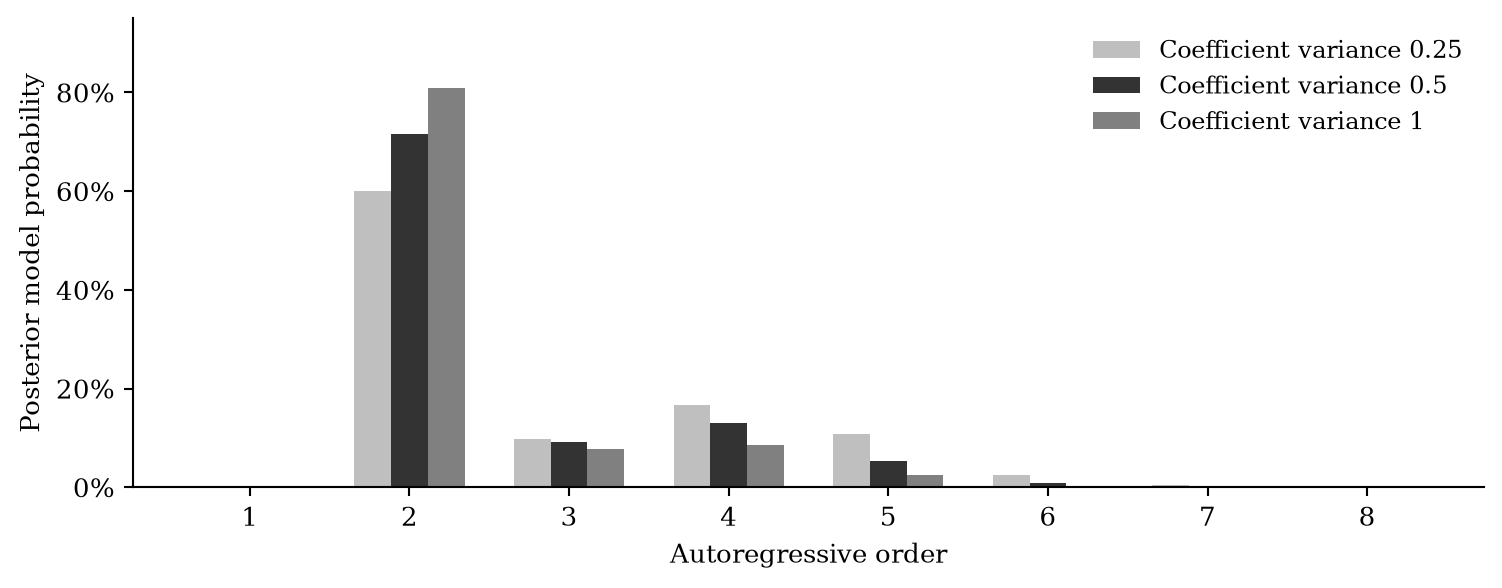

In [3]:
comparison = pd.read_csv(RESULTS / 'model_comparison.csv')
weights = comparison.pivot(index='order', columns='coefficient_variance', values='posterior_model_probability')
display(weights)
display(Image(filename=str(RESULTS / 'figures/lag_order_probabilities.png')))

## Selecting and averaging are different targets

The coefficient sum excludes the intercept. A model average mixes the scalar posterior distributions; it does not pad and average coefficient vectors. The table distinguishes weighted empirical Gibbs summaries from integrated scalar reference calculations using the same Chib weights.

,coefficient_variance,target,mean,mean_mcse_joint_batches,integration_mean,integration_sd,integration_p05,integration_p95,integration_between_model_variance_share
0,0.50,BMA,0.847708,0.000104,0.847769,0.034379,0.790141,0.902894,0.103798
1,0.50,AR8,0.800958,0.000223,0.800792,0.044488,0.727621,0.873913,0.000000
2,0.50,MAP,0.851700,0.000158,0.851774,0.031577,0.799848,0.903685,0.000000
3,1.00,BMA,0.850318,0.000106,0.850386,0.033138,0.795434,0.904156,0.057594
4,1.00,AR8,0.802217,0.000223,0.802175,0.044518,0.728967,0.875356,0.000000
5,1.00,MAP,0.852141,0.000158,0.852190,0.031583,0.800259,0.904115,0.000000
6,0.25,BMA,0.842827,0.000096,0.842977,0.036334,0.780965,0.900329,0.169873
7,0.25,AR8,0.797989,0.000222,0.798108,0.044447,0.724980,0.871139,0.000000
8,0.25,MAP,0.850754,0.000158,0.850940,0.031571,0.799016,0.902834,0.000000


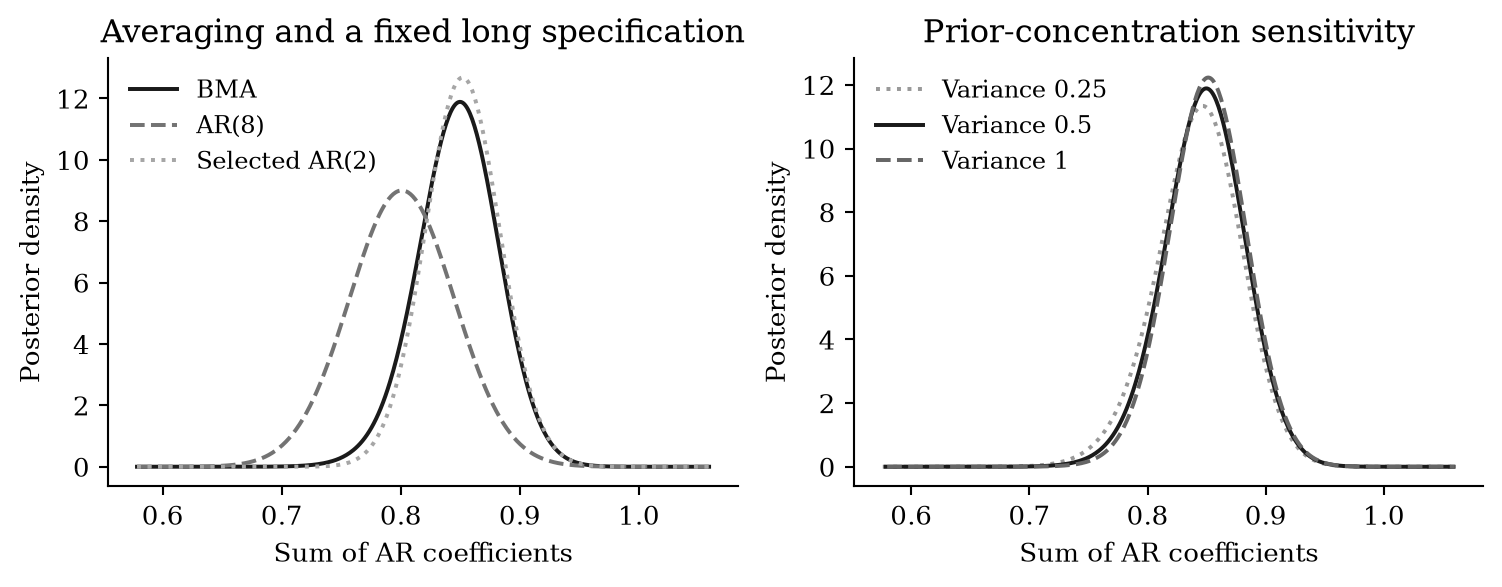

In [4]:
persistence = pd.read_csv(RESULTS / 'persistence_summary.csv')
display(persistence[['coefficient_variance', 'target', 'mean', 'mean_mcse_joint_batches', 'integration_mean', 'integration_sd', 'integration_p05', 'integration_p95', 'integration_between_model_variance_share']])
display(Image(filename=str(RESULTS / 'figures/persistence_posteriors.png')))

## A small transparent mixture control

This example is an illustrative finite mixture, not an estimate for the supplied series. The shared API computes its within- and between-component variance and samples a model index before selecting a conditional scalar draw.

In [5]:
toy = ModelAveragedInference([[0, 2], [4, 6]], [0.25, 0.75], labels=[1, 2])
display(toy.summary())
values, labels = toy.draw(50000, seed=91)
display(pd.Series({'resample_mean': values.mean(), 'second_model_fraction': np.mean(labels == 2)}))
resampling_checks = pd.read_csv(RESULTS / 'mixture_resampling_checks.csv')
display(resampling_checks[['coefficient_variance', 'resamples', 'weighted_empirical_mean', 'resample_mean', 'resampling_standard_error_of_mean']])

{'mean': 4.0,
 'median': 4.0,
 'sd': np.float64(2.0),
 'p05': 0.0,
 'p95': 6.0,
 'within_model_variance': 1.0,
 'between_model_variance': 3.0,
 'between_model_variance_share': 0.75,
 'probability_sum_above_one': 0.875}

resample_mean            3.99116
second_model_fraction    0.74926
dtype: float64

,coefficient_variance,resamples,weighted_empirical_mean,resample_mean,resampling_standard_error_of_mean
0,0.50,100000,0.847708,0.847703,0.000109
1,1.00,100000,0.850318,0.850282,0.000105
2,0.25,100000,0.842827,0.842819,0.000115


## Finite-horizon response uncertainty

The innovation is one unit at horizon zero. All draws contribute to horizons 1-10, including unstable ones. Intervals are marginal at individual horizons, not simultaneous bands. The model average acts on response distributions, not on averaged coefficients.

,coefficient_variance,target,horizon,mean,median,sd,p05,p95
1,0.5,BMA,1,1.235438,1.235071,0.069578,1.121802,1.350656
5,0.5,BMA,5,0.556733,0.545232,0.163017,0.309669,0.842032
10,0.5,BMA,10,0.080713,0.072169,0.145197,-0.148703,0.323674
12,0.5,AR8,1,1.231523,1.231746,0.073744,1.110383,1.353059
16,0.5,AR8,5,0.685460,0.675810,0.168032,0.427716,0.978978
21,0.5,AR8,10,-0.123945,-0.129439,0.174028,-0.395055,0.167682
23,0.5,MAP,1,1.230269,1.230285,0.067317,1.119681,1.340819
27,0.5,MAP,5,0.539524,0.529165,0.158115,0.299215,0.815163
32,0.5,MAP,10,0.105414,0.085072,0.118211,-0.042247,0.325696


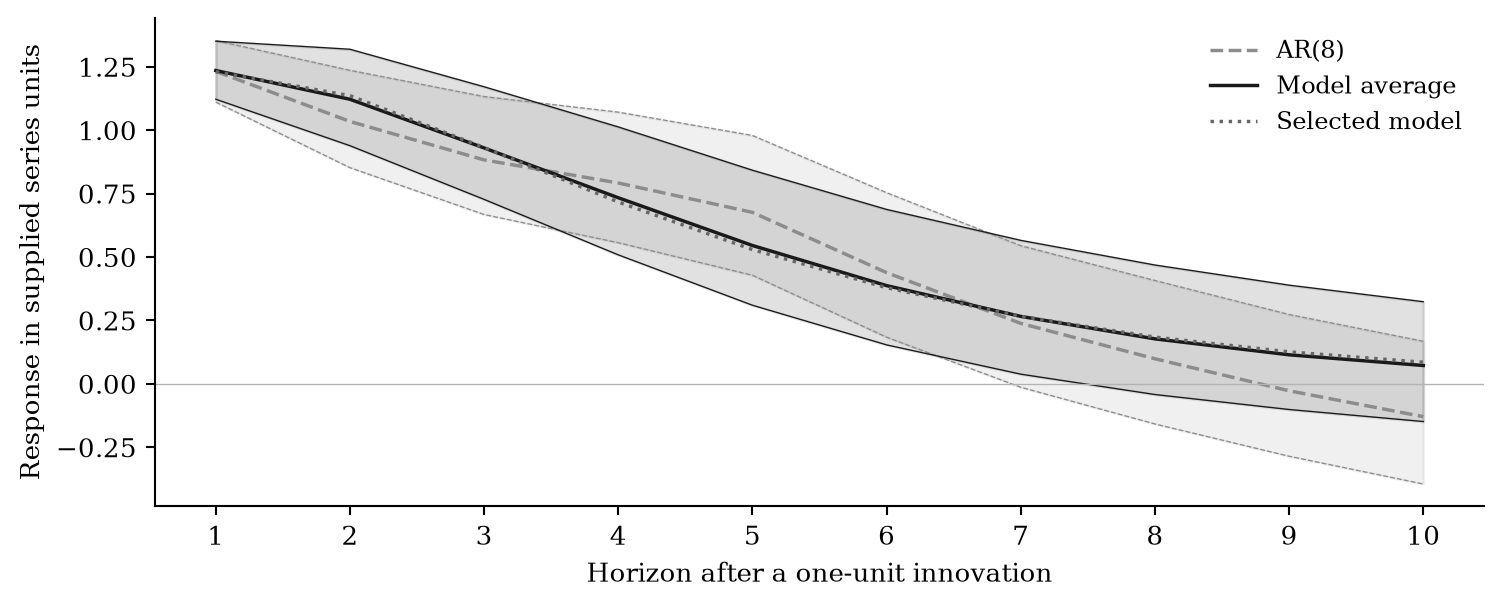

In [6]:
responses = pd.read_csv(RESULTS / 'impulse_responses.csv')
display(responses.query('coefficient_variance == 0.5 and horizon in [1, 5, 10]'))
display(Image(filename=str(RESULTS / 'figures/response_uncertainty.png')))

## Stability and rare-event resolution

The coefficient sum is not a sufficient root-stability test. Stable-draw proportions are finite-simulation frequencies. Under the primary prior, AR(2) may have zero observed unstable or sum-above-one draws while scalar integration still assigns a positive rare upper-tail probability. Resampling from the same Gibbs pools cannot recover events absent from them.

In [7]:
stability = pd.read_csv(RESULTS / 'stability.csv')
control = pd.read_csv(RESULTS / 'scalar_integration_controls.csv')
display(stability.query('coefficient_variance == 0.5')[['order', 'stable_draw_proportion', 'sum_below_one_but_not_stable_proportion', 'draws_retained', 'draws_removed_for_stability']])
display(control.query('coefficient_variance == 0.5')[['order', 'mcmc_sum_probability_above_one', 'integration_probability_sum_above_one']])

,order,stable_draw_proportion,sum_below_one_but_not_stable_proportion,draws_retained,draws_removed_for_stability
0,1,0.999300,0.000000,40000,0
1,2,1.000000,0.000000,40000,0
2,3,1.000000,0.000000,40000,0
3,4,1.000000,0.000000,40000,0
4,5,1.000000,0.000000,40000,0
5,6,1.000000,0.000000,40000,0
6,7,1.000000,0.000000,40000,0
7,8,0.999975,0.000025,40000,0


,order,mcmc_sum_probability_above_one,integration_probability_sum_above_one
0,1,0.0007,6.967225e-04
1,2,0.0000,2.255220e-06
2,3,0.0000,1.729803e-05
3,4,0.0000,1.682414e-06
4,5,0.0000,4.213645e-07
5,6,0.0000,4.258193e-07
6,7,0.0000,3.812949e-06
7,8,0.0000,5.764561e-06


## Numerical controls and convergence

The model fits retain four chains. Diagnostics cover original parameters and continuous derived quantities, not the constant horizon-zero response. Joint contiguous batches recompute model weights and sum summaries together. Monte Carlo error and between-model posterior uncertainty are different quantities.

maximum_rhat                        1.000173e+00
minimum_bulk_ess                    3.563980e+04
maximum_chib_baseline_error         3.055961e-04
maximum_svd_vs_conditional_error    5.684342e-13
maximum_point_check_error           4.156794e-03
dtype: float64

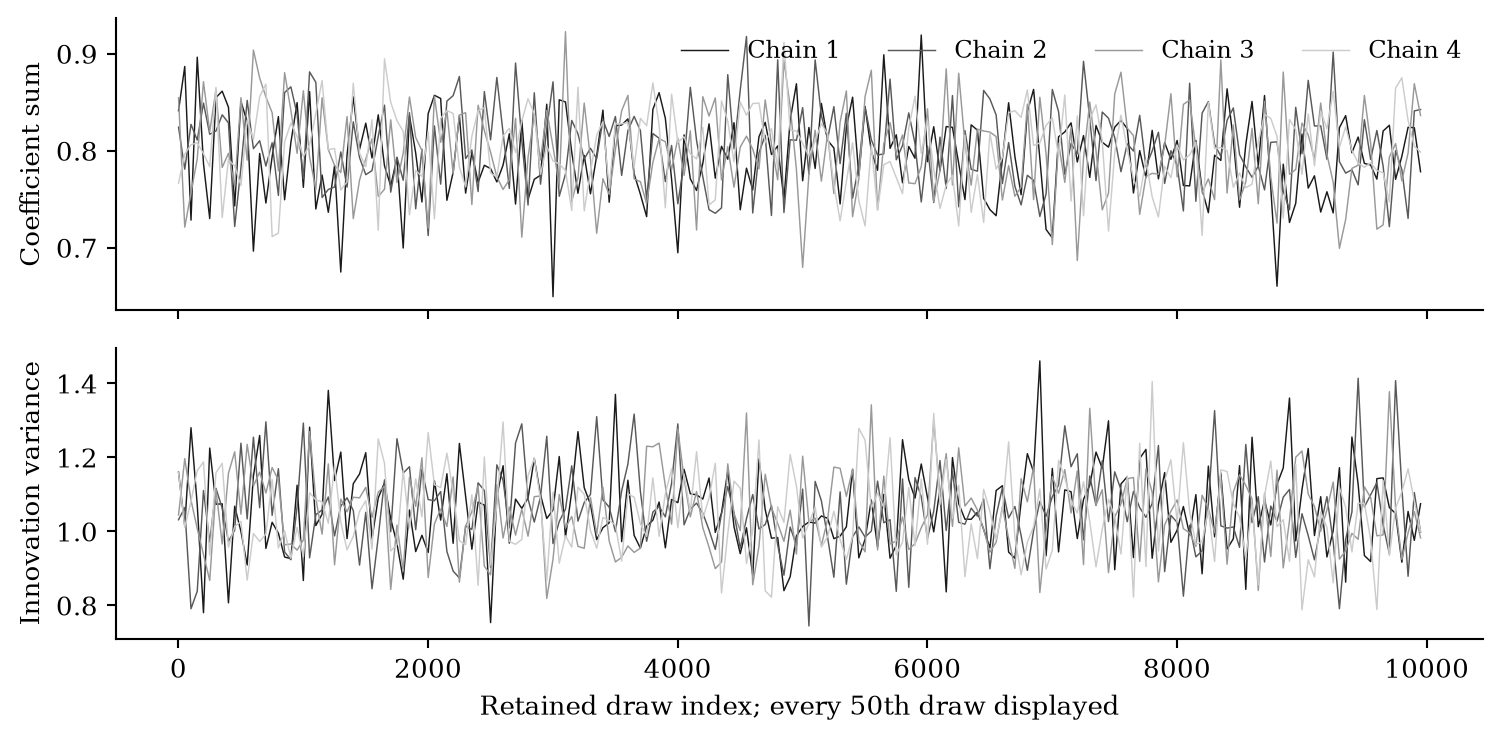

In [8]:
parameters = pd.read_csv(RESULTS / 'posterior_parameters.csv')
derived = pd.read_csv(RESULTS / 'posterior_derived.csv')
checks = pd.read_csv(RESULTS / 'evidence_point_checks.csv')
display(pd.Series({'maximum_rhat': max(parameters.r_hat.max(), derived.r_hat.max()), 'minimum_bulk_ess': min(parameters.ess_bulk.min(), derived.ess_bulk.min()), 'maximum_chib_baseline_error': comparison.absolute_chib_integration_error.max(), 'maximum_svd_vs_conditional_error': comparison.svd_vs_conditional_integration_error.max(), 'maximum_point_check_error': checks.absolute_error_vs_quadrature.max()}))
display(Image(filename=str(RESULTS / 'figures/ar8_chain_traces.png')))

## Additional normalized-prior checks

Proper-intercept and alternative Gamma-parameterization scenarios use deterministic integration at coefficient variance 0.5. They are separate checks, not extra claimed Gibbs fits or pooled prior alternatives.

In [9]:
sensitivity = pd.read_csv(RESULTS / 'additional_prior_sensitivity.csv')
display(sensitivity.query('order == 2')[['scenario', 'posterior_model_probability', 'bma_sum_mean', 'bma_sum_sd', 'bma_sum_p05', 'bma_sum_p95']])
display(load('batch_mcse.json')['0.5'])

,scenario,posterior_model_probability,bma_sum_mean,bma_sum_sd,bma_sum_p05,bma_sum_p95
1,primary,0.715359,0.847769,0.034379,0.790140,0.902894
9,intercept_variance_10,0.715358,0.847769,0.034379,0.790140,0.902894
17,intercept_variance_1000,0.715359,0.847769,0.034379,0.790140,0.902894
25,precision_mean_degree_alternative,0.708541,0.847576,0.034162,0.790243,0.902292


{'method': 'joint contiguous batches preserving each chain; common pooled evaluation point',
 'batch_size': 1000,
 'batches': 40,
 'mcse': {'bma_mean': 0.00010367146748391561,
  'bma_probability_sum_above_one': 4.578366900244793e-10,
  'bma_p05': 0.0002487102100810604,
  'bma_median': 0.00013320431107786515,
  'bma_p95': 0.0002765785303868321,
  'weight_ar1': 4.065433858892849e-10,
  'weight_ar2': 2.301122144454552e-05,
  'weight_ar3': 1.1218603443188832e-05,
  'weight_ar4': 1.9162098977104406e-05,
  'weight_ar5': 7.631692328557646e-06,
  'weight_ar6': 1.416914909962414e-06,
  'weight_ar7': 2.195911346013072e-07,
  'weight_ar8': 2.597018748106915e-08},
 'interpretation': 'Numerical Monte Carlo uncertainty; distinct from posterior model uncertainty',
 'zero_event_note': 'Zero sampled tail events do not establish zero posterior probability'}

## Reproduction and scope

All source/data settings are recorded. Public tables and this notebook can be inspected without the external CSV; a full rerun requires its matching bytes. Private archives are excluded from Git. Source and output checksums identify the recorded calculation, while scientific controls support numerical verification.

The study does not identify the unknown generating process, establish a macroeconomic causal effect, or evaluate forecast performance. Read the report for the interpretation of model sensitivity, pointwise responses, and rare-event limits.

In [10]:
display(load('run_metadata.json'))
print('All recorded fit controls passed:', validation['all_passed'])

{'sampler': {'draws': 10000, 'warmup': 3000, 'chains': 4, 'seed': 20261117},
 'seed_rule': 'base seed + scenario index * 10000 + order * 100; separate spawned chain streams',
 'coefficient_variance_order': [0.5, 1.0, 0.25],
 'intercept_variance': 100.0,
 'precision_prior': {'shape': 1.0, 'rate': 3.0},
 'model_prior': 'equal probability 1/8 within each separate sensitivity analysis',
 'model_orders': [1, 2, 3, 4, 5, 6, 7, 8],
 'python': '3.12.14',
 'platform': 'Darwin',
 'packages': {'numpy': '2.5.4',
  'scipy': '1.18.1',
  'pandas': '3.1.1',
  'matplotlib': '3.11.2',
  'arviz': '0.23.4',
  'bayes-policy': '0.1.0',
  'shock-dynamics': '0.1.0'},
 'units': 'unspecified series units and generic observation periods; no empirical calendar assigned'}

All recorded fit controls passed: True
